<a href="https://colab.research.google.com/github/dldustj0715/AI_study/blob/main/HAR/Exp1_InceptionTime.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# UCI HAR — Exp 1: InceptionTime
 `build_model()`만 InceptionTime 계열 구조로 교체

입력 `(N, 128, 9)` → Inception 모듈 6개(커널 9/19/39, 병렬 풀링 분기) → Residual 연결 → Global Average Pooling → Softmax 6개 클래스.


## 0. 데이터 다운로드


In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import os
import zipfile

zip_path = "/content/drive/MyDrive/Colab Notebooks/UCI HAR Dataset.zip"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall("/content")

print("압축 해제 완료!")

압축 해제 완료!


In [3]:
DATASET_PATH = "/content/UCI HAR Dataset"

print(os.path.exists(DATASET_PATH))
print(os.listdir(DATASET_PATH))

True
['.DS_Store', 'activity_labels.txt', 'features.txt', 'test', 'train', 'README.txt', 'features_info.txt']


In [4]:
#!/usr/bin/env python3
# -*- coding: utf-8 -*-

"""
UCI-HAR Classification using CNN + LSTM
TensorFlow / Keras

Input:
    UCI-HAR Inertial Signals
    Shape = (samples, 128, 9)

Channels:
    body_acc_x
    body_acc_y
    body_acc_z
    body_gyro_x
    body_gyro_y
    body_gyro_z
    total_acc_x
    total_acc_y
    total_acc_z

Classes:
    0: WALKING
    1: WALKING_UPSTAIRS
    2: WALKING_DOWNSTAIRS
    3: SITTING
    4: STANDING
    5: LAYING
"""

'\nUCI-HAR Classification using CNN + LSTM\nTensorFlow / Keras\n\nInput:\n    UCI-HAR Inertial Signals\n    Shape = (samples, 128, 9)\n\nChannels:\n    body_acc_x\n    body_acc_y\n    body_acc_z\n    body_gyro_x\n    body_gyro_y\n    body_gyro_z\n    total_acc_x\n    total_acc_y\n    total_acc_z\n\nClasses:\n    0: WALKING\n    1: WALKING_UPSTAIRS\n    2: WALKING_DOWNSTAIRS\n    3: SITTING\n    4: STANDING\n    5: LAYING\n'

## 1. CONFIGURATION

In [5]:
# ============================================================
# 1. CONFIGURATION
# ============================================================

DATASET_PATH = "/content/UCI HAR Dataset"

SEED = 42
VALIDATION_RATIO = 0.20

BATCH_SIZE = 64
EPOCHS = 100
LEARNING_RATE = 0.001

MODEL_PATH = "best_inceptiontime_uci_har.keras"

## 2. IMPORT LIBRARIES

In [6]:
# ============================================================
# 2. IMPORT LIBRARIES
# ============================================================

import os
import random
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

from tensorflow.keras import Model

from tensorflow.keras.layers import (
    Input, Conv1D, MaxPooling1D, BatchNormalization,
    Dense, Dropout, Concatenate, Add, Activation,
    GlobalAveragePooling1D
)

from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau,
    ModelCheckpoint
)

## 3. RANDOM SEED

In [7]:
# ============================================================
# 3. RANDOM SEED
# ============================================================

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)


print("=" * 70)
print("TensorFlow version:", tf.__version__)
print("=" * 70)

TensorFlow version: 2.21.0


## 4. SIGNAL / CLASS NAMES

In [8]:
# ============================================================
# 4. SIGNAL / CLASS NAMES
# ============================================================

SIGNAL_NAMES = [
    "body_acc_x",
    "body_acc_y",
    "body_acc_z",

    "body_gyro_x",
    "body_gyro_y",
    "body_gyro_z",

    "total_acc_x",
    "total_acc_y",
    "total_acc_z"
]


CLASS_NAMES = [
    "WALKING",
    "WALKING_UPSTAIRS",
    "WALKING_DOWNSTAIRS",
    "SITTING",
    "STANDING",
    "LAYING"
]

## 5. LOAD INERTIAL SIGNALS

In [9]:
# ============================================================
# 5. LOAD INERTIAL SIGNALS
# ============================================================

def load_inertial_signals(dataset_path, split):

    """
    Load 9-channel UCI-HAR inertial signals.

    Each signal file:
        shape = (N, 128)

    After stacking:
        shape = (N, 128, 9)
    """

    signal_folder = os.path.join(
        dataset_path,
        split,
        "Inertial Signals"
    )

    signals = []

    for signal_name in SIGNAL_NAMES:

        filename = f"{signal_name}_{split}.txt"

        file_path = os.path.join(
            signal_folder,
            filename
        )

        if not os.path.exists(file_path):
            raise FileNotFoundError(
                f"File not found: {file_path}"
            )

        signal = np.loadtxt(
            file_path,
            dtype=np.float32
        )

        print(
            f"{split:5s} | "
            f"{signal_name:20s} | "
            f"{signal.shape}"
        )

        signals.append(signal)

    # (N, 128, 9)
    X = np.stack(
        signals,
        axis=-1
    )

    return X

## 6. LOAD LABELS

In [10]:
# ============================================================
# 6. LOAD LABELS
# ============================================================

def load_labels(dataset_path, split):

    label_path = os.path.join(
        dataset_path,
        split,
        f"y_{split}.txt"
    )

    y = np.loadtxt(
        label_path,
        dtype=np.int32
    )

    # Original UCI-HAR labels:
    # 1 ~ 6
    #
    # TensorFlow:
    # 0 ~ 5

    y = y - 1

    return y

## 7. LOAD TRAIN / TEST DATA

In [11]:
# ============================================================
# 7. LOAD TRAIN / TEST DATA
# ============================================================

print("\nLoading training data...\n")

X_train_full = load_inertial_signals(
    DATASET_PATH,
    "train"
)

y_train_full = load_labels(
    DATASET_PATH,
    "train"
)


print("\nLoading test data...\n")

X_test = load_inertial_signals(
    DATASET_PATH,
    "test"
)

y_test = load_labels(
    DATASET_PATH,
    "test"
)


print("\n" + "=" * 70)
print("Original dataset")
print("=" * 70)

print(
    "X_train_full:",
    X_train_full.shape
)

print(
    "y_train_full:",
    y_train_full.shape
)

print(
    "X_test:",
    X_test.shape
)

print(
    "y_test:",
    y_test.shape
)


Loading training data...

train | body_acc_x           | (7352, 128)
train | body_acc_y           | (7352, 128)
train | body_acc_z           | (7352, 128)
train | body_gyro_x          | (7352, 128)
train | body_gyro_y          | (7352, 128)
train | body_gyro_z          | (7352, 128)
train | total_acc_x          | (7352, 128)
train | total_acc_y          | (7352, 128)
train | total_acc_z          | (7352, 128)

Loading test data...

test  | body_acc_x           | (2947, 128)
test  | body_acc_y           | (2947, 128)
test  | body_acc_z           | (2947, 128)
test  | body_gyro_x          | (2947, 128)
test  | body_gyro_y          | (2947, 128)
test  | body_gyro_z          | (2947, 128)
test  | total_acc_x          | (2947, 128)
test  | total_acc_y          | (2947, 128)
test  | total_acc_z          | (2947, 128)

Original dataset
X_train_full: (7352, 128, 9)
y_train_full: (7352,)
X_test: (2947, 128, 9)
y_test: (2947,)


## 8. TRAIN / VALIDATION SPLIT

In [12]:
# ============================================================
# 8. TRAIN / VALIDATION SPLIT
# ============================================================

X_train, X_val, y_train, y_val = train_test_split(

    X_train_full,
    y_train_full,

    test_size=VALIDATION_RATIO,

    random_state=SEED,

    stratify=y_train_full
)


print("\n" + "=" * 70)
print("Dataset split")
print("=" * 70)

print(
    "Train:",
    X_train.shape
)

print(
    "Validation:",
    X_val.shape
)

print(
    "Test:",
    X_test.shape
)


Dataset split
Train: (5881, 128, 9)
Validation: (1471, 128, 9)
Test: (2947, 128, 9)


## 9. STANDARD SCALER

In [13]:
# ============================================================
# 9. STANDARD SCALER
# ============================================================

"""
Original shape:

    (samples, 128, 9)

StandardScaler requires:

    (observations, features)

Therefore reshape:

    (samples * 128, 9)

The 9 sensor channels are standardized independently.

IMPORTANT:
    scaler.fit() is performed ONLY on training data.
"""


num_channels = X_train.shape[-1]

scaler = StandardScaler()


# ------------------------------------------------------------
# Fit scaler using training data only
# ------------------------------------------------------------

X_train_2d = X_train.reshape(
    -1,
    num_channels
)

scaler.fit(
    X_train_2d
)


# ------------------------------------------------------------
# Transform function
# ------------------------------------------------------------

def standardize_data(X, scaler):

    original_shape = X.shape

    X_2d = X.reshape(
        -1,
        original_shape[-1]
    )

    X_scaled = scaler.transform(
        X_2d
    )

    X_scaled = X_scaled.reshape(
        original_shape
    )

    return X_scaled.astype(
        np.float32
    )


# ------------------------------------------------------------
# Apply StandardScaler
# ------------------------------------------------------------

X_train = standardize_data(
    X_train,
    scaler
)

X_val = standardize_data(
    X_val,
    scaler
)

X_test = standardize_data(
    X_test,
    scaler
)


print("\n" + "=" * 70)
print("StandardScaler")
print("=" * 70)

print(
    "Training channel means:"
)

print(
    np.round(
        np.mean(
            X_train,
            axis=(0, 1)
        ),
        4
    )
)

print(
    "\nTraining channel standard deviations:"
)

print(
    np.round(
        np.std(
            X_train,
            axis=(0, 1)
        ),
        4
    )
)


StandardScaler
Training channel means:
[ 0.  0.  0.  0.  0. -0.  0. -0.  0.]

Training channel standard deviations:
[0.9997 0.9995 0.9994 0.9997 0.9996 0.9996 0.9997 0.9998 0.9998]


## 10. BUILD INCEPTIONTIME MODEL (EXP 1)

In [14]:
# ============================================================
# 10. BUILD INCEPTIONTIME MODEL (EXP 1)
# ============================================================
# InceptionTime-style network:
# - multi-scale convolution branches
# - 1x1 bottleneck to reduce channel count
# - same-padding, stride=1 to preserve temporal length
# - residual shortcuts every 3 Inception modules
# - global average pooling + 6-class softmax
#
# Input  : (batch, 128, 9)
# Output : (batch, 6)

def inception_module(x, filters=32, kernel_sizes=(9, 19, 39), bottleneck=32):
    # Bottleneck: reduce the input channels before large convolutions.
    z = Conv1D(bottleneck, 1, padding="same", use_bias=False)(x)

    branches = [
        Conv1D(filters, k, padding="same", use_bias=False)(z)
        for k in kernel_sizes
    ]

    # A pooling branch retains temporal length (pool_size=3, stride=1).
    pooled = MaxPooling1D(pool_size=3, strides=1, padding="same")(x)
    pooled = Conv1D(filters, 1, padding="same", use_bias=False)(pooled)

    x = Concatenate(axis=-1)(branches + [pooled])
    x = BatchNormalization()(x)
    return Activation("relu")(x)


def residual_add(x, shortcut):
    # Match channel dimensions before addition.
    shortcut = Conv1D(int(x.shape[-1]), 1, padding="same",
                      use_bias=False)(shortcut)
    shortcut = BatchNormalization()(shortcut)
    x = Add()([x, shortcut])
    return Activation("relu")(x)


def build_model():
    inputs = Input(shape=(128, 9))
    x = inputs

    # Two groups of three Inception modules, each with a residual shortcut.
    for _ in range(2):
        shortcut = x
        for _ in range(3):
            x = inception_module(x)
        x = residual_add(x, shortcut)

    # Temporal aggregation occurs only at the classifier stage.
    x = GlobalAveragePooling1D()(x)
    x = Dropout(0.30)(x)
    outputs = Dense(6, activation="softmax")(x)

    return Model(inputs=inputs, outputs=outputs, name="InceptionTime_UCI_HAR")


model = build_model()

## 11. COMPILE

In [15]:
# ============================================================
# 11. COMPILE
# ============================================================

optimizer = tf.keras.optimizers.Adam(
    learning_rate=LEARNING_RATE
)


model.compile(

    optimizer=optimizer,

    loss="sparse_categorical_crossentropy",

    metrics=[
        "accuracy"
    ]
)


print("\n")
model.summary()

Model: "InceptionTime_UCI_HAR"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 128, 9)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d (Conv1D)     │ (None, 128, 32)   │        288 │ input_layer[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d       │ (None, 128, 9)    │          0 │ input_layer[0][0] │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_1 (Conv1D)   │ (None, 128, 32)   │      9,216 │ conv1d[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_2 (Conv1D)   │ (None, 128, 32)   │     19,456 │ conv1d[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_3 (Conv1D)   │ (None, 128, 32)   │     39,936 │ conv1d[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_4 (Conv1D)   │ (None, 128, 32)   │        288 │ max_pooling1d[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 128, 128)  │          0 │ conv1d_1[0][0],   │
│ (Concatenate)       │                   │            │ conv1d_2[0][0],   │
│                     │                   │            │ conv1d_3[0][0],   │
│                     │                   │            │ conv1d_4[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 128, 128)  │        512 │ concatenate[0][0] │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 128, 128)  │          0 │ batch_normalizat… │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_5 (Conv1D)   │ (None, 128, 32)   │      4,096 │ activation[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_1     │ (None, 128, 128)  │          0 │ activation[0][0]  │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_6 (Conv1D)   │ (None, 128, 32)   │      9,216 │ conv1d_5[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_7 (Conv1D)   │ (None, 128, 32)   │     19,456 │ conv1d_5[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_8 (Conv1D)   │ (None, 128, 32)   │     39,936 │ conv1d_5[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_9 (Conv1D)   │ (None, 128, 32)   │      4,096 │ max_pooling1d_1[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_1       │ (None, 128, 128)  │          0 │ conv1d_6[0][0],   │
│ (Concatenate)       │                   │            │ conv1d_7[0][0],   │
│                     │                   │            │ conv1d_8[0][0],   │
│                     │                   │            │ conv1d_9[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 128)  │        512 │ concatenate_1[0]… │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 128, 128)  │          0 │ batch_normalizat

 Total params: 475,590 (1.81 MB)

 Trainable params: 473,542 (1.81 MB)

 Non-trainable params: 2,048 (8.00 KB)

## 12. CALLBACKS

In [16]:
# ============================================================
# 12. CALLBACKS
# ============================================================

callbacks = [

    EarlyStopping(

        monitor="val_loss",

        patience=15,

        restore_best_weights=True,

        verbose=1
    ),


    ReduceLROnPlateau(

        monitor="val_loss",

        factor=0.5,

        patience=5,

        min_lr=1e-6,

        verbose=1
    ),


    ModelCheckpoint(

        filepath=MODEL_PATH,

        monitor="val_loss",

        save_best_only=True,

        verbose=1
    )
]

## 13. TRAIN

In [17]:
# ============================================================
# 13. TRAIN
# ============================================================

print("\n" + "=" * 70)
print("Training InceptionTime")
print("=" * 70)


history = model.fit(

    X_train,
    y_train,

    validation_data=(
        X_val,
        y_val
    ),

    epochs=EPOCHS,

    batch_size=BATCH_SIZE,

    callbacks=callbacks,

    verbose=1
)


Training InceptionTime
Epoch 1/100
92/92 ━━━━━━━━━━━━━━━━━━━━ 0s 185ms/step - accuracy: 0.8445 - loss: 0.4253
Epoch 1: val_loss improved from None to 0.18951, saving model to best_inceptiontime_uci_har.keras

Epoch 1: finished saving model to best_inceptiontime_uci_har.keras
92/92 ━━━━━━━━━━━━━━━━━━━━ 53s 310ms/step - accuracy: 0.9131 - loss: 0.2278 - val_accuracy: 0.9341 - val_loss: 0.1895 - learning_rate: 0.0010
Epoch 2/100
92/92 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.9428 - loss: 0.1322
Epoch 2: val_loss improved from 0.18951 to 0.13228, saving model to best_inceptiontime_uci_har.keras

Epoch 2: finished saving model to best_inceptiontime_uci_har.keras
92/92 ━━━━━━━━━━━━━━━━━━━━ 2s 24ms/step - accuracy: 0.9430 - loss: 0.1305 - val_accuracy: 0.9558 - val_loss: 0.1323 - learning_rate: 0.0010
Epoch 3/100
91/92 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.9487 - loss: 0.1182
Epoch 3: val_loss improved from 0.13228 to 0.10667, saving model to best_inceptiontime_uci_har.keras

## 14. LOAD BEST MODEL

In [18]:
# ============================================================
# 14. LOAD BEST MODEL
# ============================================================

model = tf.keras.models.load_model(
    MODEL_PATH
)

## 15. TEST PREDICTION

In [19]:
# ============================================================
# 15. TEST PREDICTION
# ============================================================

test_loss, test_accuracy = model.evaluate(

    X_test,
    y_test,

    batch_size=BATCH_SIZE,

    verbose=0
)


y_prob = model.predict(

    X_test,

    batch_size=BATCH_SIZE,

    verbose=0
)


y_pred = np.argmax(
    y_prob,
    axis=1
)

## 16. PERFORMANCE METRICS

In [20]:
# ============================================================
# 16. PERFORMANCE METRICS
# ============================================================

accuracy = accuracy_score(
    y_test,
    y_pred
)


macro_precision = precision_score(

    y_test,
    y_pred,

    average="macro",

    zero_division=0
)


macro_recall = recall_score(

    y_test,
    y_pred,

    average="macro",

    zero_division=0
)


macro_f1 = f1_score(

    y_test,
    y_pred,

    average="macro",

    zero_division=0
)


weighted_f1 = f1_score(

    y_test,
    y_pred,

    average="weighted",

    zero_division=0
)


print("\n" + "=" * 70)
print("TEST RESULTS")
print("=" * 70)

print(
    f"Test Loss        : {test_loss:.4f}"
)

print(
    f"Accuracy         : {accuracy:.4f}"
)

print(
    f"Macro Precision  : {macro_precision:.4f}"
)

print(
    f"Macro Recall     : {macro_recall:.4f}"
)

print(
    f"Macro F1         : {macro_f1:.4f}"
)

print(
    f"Weighted F1      : {weighted_f1:.4f}"
)


TEST RESULTS
Test Loss        : 0.4439
Accuracy         : 0.9427
Macro Precision  : 0.9447
Macro Recall     : 0.9434
Macro F1         : 0.9429
Weighted F1      : 0.9425


## 17. CLASSIFICATION REPORT

In [21]:
# ============================================================
# 17. CLASSIFICATION REPORT
# ============================================================

print("\n" + "=" * 70)
print("CLASSIFICATION REPORT")
print("=" * 70)


print(

    classification_report(

        y_test,
        y_pred,

        target_names=CLASS_NAMES,

        digits=4,

        zero_division=0
    )
)


CLASSIFICATION REPORT
                    precision    recall  f1-score   support

           WALKING     0.9979    0.9698    0.9836       496
  WALKING_UPSTAIRS     0.9978    0.9490    0.9728       471
WALKING_DOWNSTAIRS     0.9170    1.0000    0.9567       420
           SITTING     0.9093    0.8167    0.8605       491
          STANDING     0.8497    0.9248    0.8857       532
            LAYING     0.9963    1.0000    0.9981       537

          accuracy                         0.9427      2947
         macro avg     0.9447    0.9434    0.9429      2947
      weighted avg     0.9446    0.9427    0.9425      2947



## 18. CONFUSION MATRIX

In [22]:
# ============================================================
# 18. CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    y_test,
    y_pred
)


print("\nConfusion Matrix")

print(cm)


Confusion Matrix
[[481   0  15   0   0   0]
 [  1 447  23   0   0   0]
 [  0   0 420   0   0   0]
 [  0   1   0 401  87   2]
 [  0   0   0  40 492   0]
 [  0   0   0   0   0 537]]


## 19. NORMALIZED CONFUSION MATRIX

In [23]:
# ============================================================
# 19. NORMALIZED CONFUSION MATRIX
# ============================================================

cm_normalized = (

    cm.astype(np.float32)

    / np.maximum(
        cm.sum(
            axis=1,
            keepdims=True
        ),
        1
    )
)


print("\nNormalized Confusion Matrix")

print(
    np.round(
        cm_normalized,
        4
    )
)


Normalized Confusion Matrix
[[0.9698 0.     0.0302 0.     0.     0.    ]
 [0.0021 0.949  0.0488 0.     0.     0.    ]
 [0.     0.     1.     0.     0.     0.    ]
 [0.     0.002  0.     0.8167 0.1772 0.0041]
 [0.     0.     0.     0.0752 0.9248 0.    ]
 [0.     0.     0.     0.     0.     1.    ]]


## 20. PLOT CONFUSION MATRIX

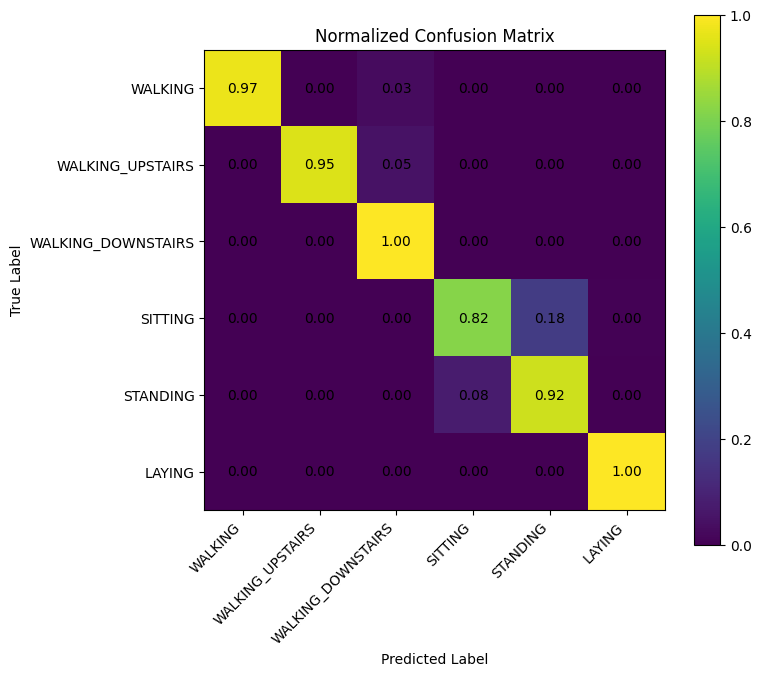

In [24]:
# ============================================================
# 20. PLOT CONFUSION MATRIX
# ============================================================

plt.figure(
    figsize=(8, 7)
)


plt.imshow(
    cm_normalized
)


plt.colorbar()


plt.xticks(

    np.arange(
        len(CLASS_NAMES)
    ),

    CLASS_NAMES,

    rotation=45,

    ha="right"
)


plt.yticks(

    np.arange(
        len(CLASS_NAMES)
    ),

    CLASS_NAMES
)


plt.xlabel(
    "Predicted Label"
)

plt.ylabel(
    "True Label"
)

plt.title(
    "Normalized Confusion Matrix"
)


for i in range(
    len(CLASS_NAMES)
):

    for j in range(
        len(CLASS_NAMES)
    ):

        plt.text(

            j,
            i,

            f"{cm_normalized[i, j]:.2f}",

            ha="center",

            va="center"
        )


plt.tight_layout()

plt.savefig(
    "confusion_matrix_inceptiontime.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 21. TRAINING LOSS

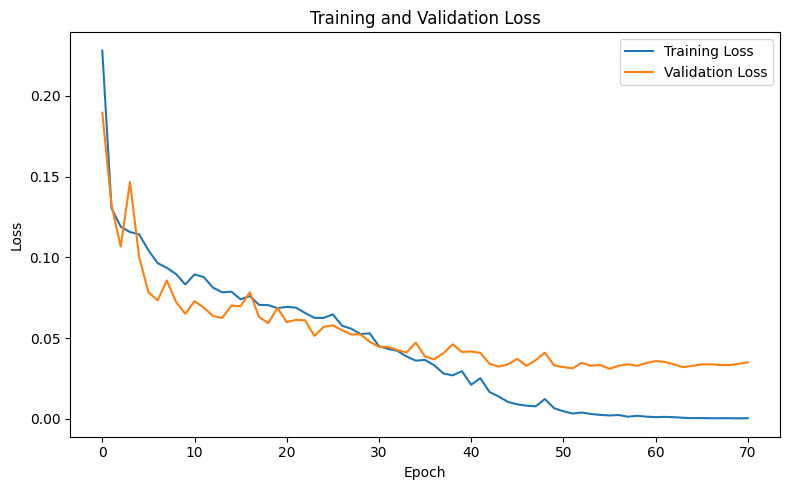

In [25]:
# ============================================================
# 21. TRAINING LOSS
# ============================================================

plt.figure(
    figsize=(8, 5)
)


plt.plot(
    history.history["loss"],
    label="Training Loss"
)


plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)


plt.xlabel(
    "Epoch"
)

plt.ylabel(
    "Loss"
)

plt.title(
    "Training and Validation Loss"
)

plt.legend()

plt.tight_layout()

plt.show()

## 22. TRAINING ACCURACY

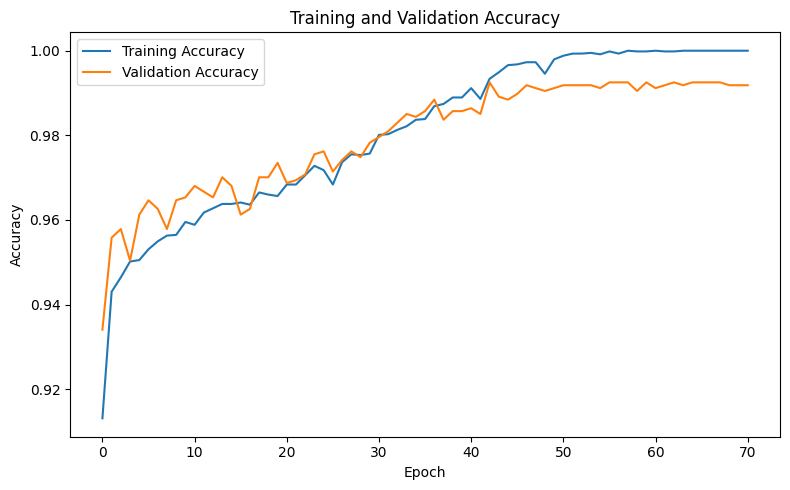


Finished.


In [26]:
# ============================================================
# 22. TRAINING ACCURACY
# ============================================================

plt.figure(
    figsize=(8, 5)
)


plt.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)


plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)


plt.xlabel(
    "Epoch"
)

plt.ylabel(
    "Accuracy"
)

plt.title(
    "Training and Validation Accuracy"
)

plt.legend()

plt.tight_layout()

plt.show()


print("\nFinished.")